## Importing Libraries

In [1]:
# For data manipulation
import numpy as np
import pandas as pd

# For fetch financial data
import yfinance as yf

# For visualization
import matplotlib.pyplot as plt
%matplotlib inline
plt.style.use('seaborn-v0_8-darkgrid')

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

## Daily FX Price Data

In [3]:
# Set the ticker as 'EURUSD=X'
forex_data = yf.download('EURUSD=X', start='2019-01-01')

# Set the index  to a datetime object
forex_data.index = pd.to_datetime(forex_data.index)

forex_data.tail()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,EURUSD=X,EURUSD=X,EURUSD=X,EURUSD=X,EURUSD=X
Date,,,,,
2026-08-07,1.152472,1.157943,1.151848,1.152326,0
2026-08-10,1.155642,1.156604,1.154454,1.155575,0
2026-08-11,1.154641,1.155268,1.153203,1.154668,0
2026-08-12,1.154374,1.156243,1.153270,1.154348,0
2026-08-13,1.154068,1.154201,1.151543,1.152605,0


## Plot the Close Price

<Figure size 1000x700 with 0 Axes>

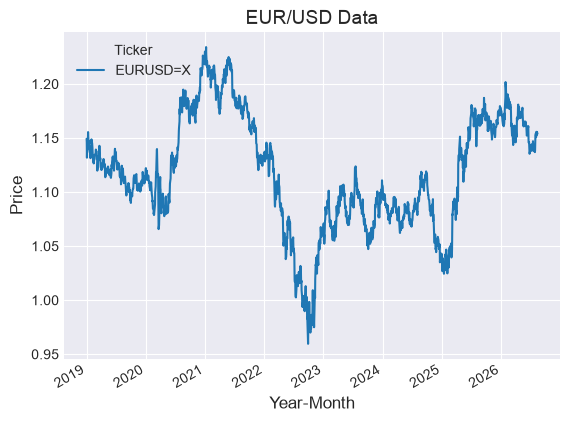

In [4]:
# Plot the close price
plt.figure(figsize=(10, 7))
forex_data['Close'].plot()

# Set the title and axis label
plt.title('EUR/USD Data', fontsize=14)
plt.xlabel('Year-Month', fontsize=12)
plt.ylabel('Price', fontsize=12)

# Show the plot
plt.show()

## Minute FX Price Data

In [12]:
forex_data_minute = yf.download('EURUSD=X', period='5d', interval='1m')

# Set the index to a datetime object
forex_data_minute.index = pd.to_datetime(forex_data_minute.index)

forex_data_minute.tail()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,EURUSD=X,EURUSD=X,EURUSD=X,EURUSD=X,EURUSD=X
Datetime,,,,,
2026-08-13 12:12:00+01:00,1.154068,1.154068,1.154068,1.154068,0
2026-08-13 12:13:00+01:00,1.154068,1.154068,1.154068,1.154068,0
2026-08-13 12:14:00+01:00,1.154201,1.154201,1.154201,1.154201,0
2026-08-13 12:15:00+01:00,1.154201,1.154201,1.154201,1.154201,0
2026-08-13 12:16:00+01:00,1.154068,1.154068,1.154068,1.154068,0


In [13]:
def format_xlabels(data, ax):
    """
    This function will format the x-labels of the graph
    """
    num_x_values = data.shape[0]
    step_size = num_x_values // 4

    ax.set_xticks(np.arange(num_x_values))
    ax.set_xticklabels(data.index.values, rotation=45)

    for i, label in enumerate(ax.get_xticklabels()):
        if not i%step_size==0:
            label.set_visible(False)
    label.set_visible(True)

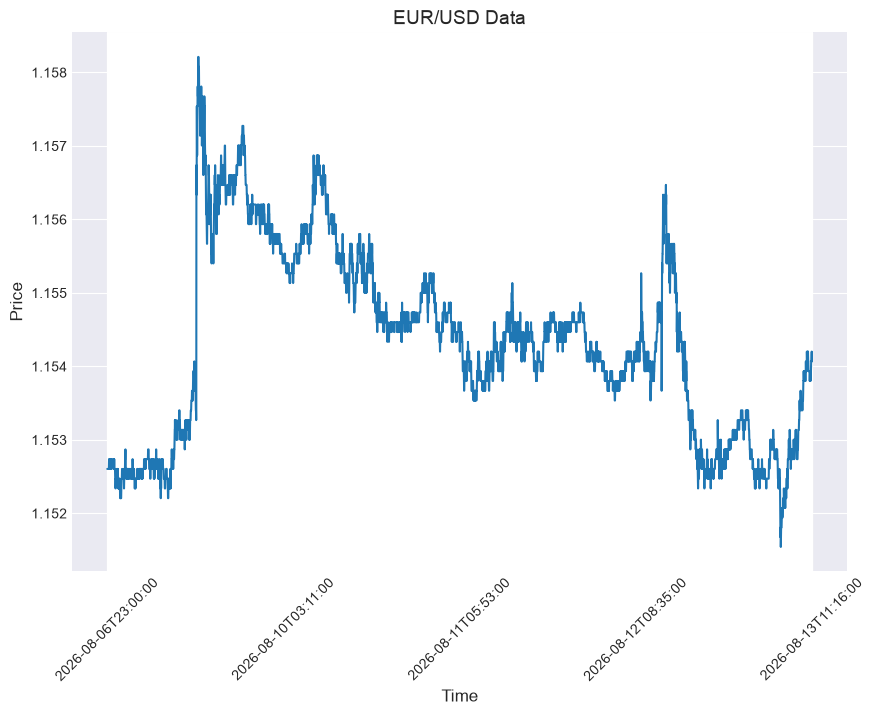

In [14]:
# Number of points to plot
x_values = forex_data_minute['Close'].shape[0]

# Plot the series
fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(range(x_values), forex_data_minute['Close'])

# Set title and axis label
plt.title('EUR/USD Data', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('Price', fontsize=12)

# Format the xlabel
format_xlabels(forex_data_minute['Close'], ax)
plt.show()

## EURCHF

In [15]:
ch_forex_data_minute = yf.download('EURCHF=X', period='5d', interval='1m')
ch_forex_data_minute.index = pd.to_datetime(ch_forex_data_minute.index)
ch_forex_data_minute.tail()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,EURCHF=X,EURCHF=X,EURCHF=X,EURCHF=X,EURCHF=X
Datetime,,,,,
2026-08-13 12:25:00+01:00,0.93712,0.93720,0.93668,0.93713,0
2026-08-13 12:26:00+01:00,0.93710,0.93720,0.93709,0.93712,0
2026-08-13 12:27:00+01:00,0.93704,0.93710,0.93661,0.93710,0
2026-08-13 12:28:00+01:00,0.93704,0.93710,0.93699,0.93704,0
2026-08-13 12:29:00+01:00,0.93705,0.93705,0.93705,0.93705,0


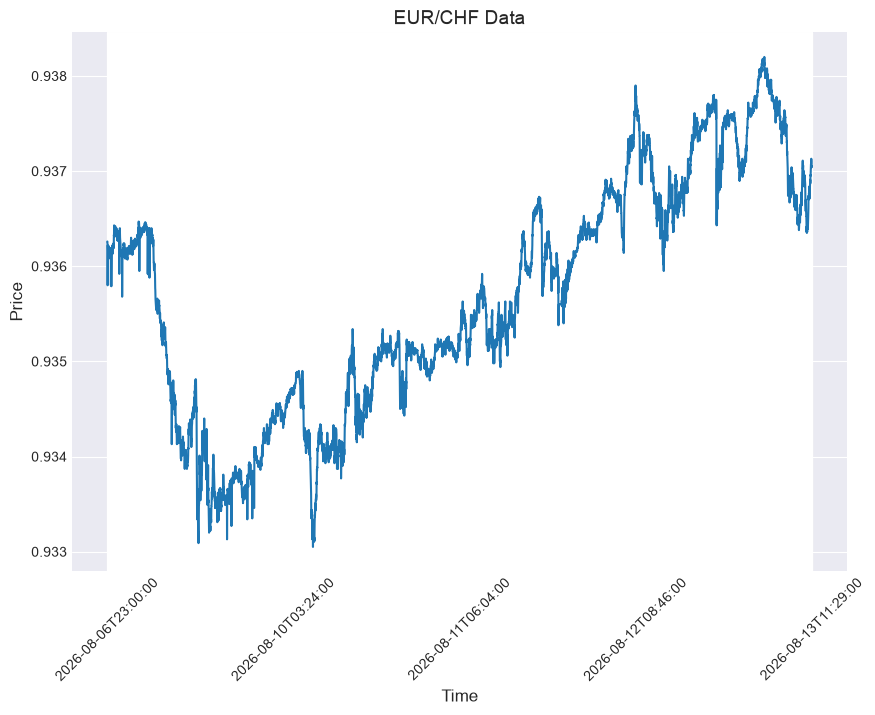

In [16]:
# Number of points to plot
ch_x_values = ch_forex_data_minute['Close'].shape[0]

# Plot the series
fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(range(ch_x_values), ch_forex_data_minute['Close'])

# Set title and axis label
plt.title('EUR/CHF Data', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('Price', fontsize=12)

# Format the xlabel
format_xlabels(ch_forex_data_minute['Close'], ax)
plt.show()